# 01_07 Discrete Distributions: Summary and Chooser

**Learning objectives**
- Compare all Module 01 distributions in one table, with numbers computed by `scipy`.
- Pick the right distribution for a scenario using a decision flowchart.
- See how the distributions are related (limits, special cases, sums).
- Practice on mixed problems and 5 short real scenarios.

**Prerequisites:** lessons [01_01](01_01_bernoulli_binomial.ipynb) to [01_06](01_06_zipf_power_laws.ipynb).

## 1. Setup

All imports in one cell, seeded generator for reproducibility.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

Each distribution answers a different question about a random count or category:

- **Bernoulli / Binomial:** successes in a fixed number of independent trials.
- **Geometric / Negative Binomial:** trials until the first / r-th success.
- **Poisson:** events in a window at a constant rate.
- **Hypergeometric:** successes when sampling without replacement.
- **Discrete uniform / Categorical / Multinomial:** which category, and how many of each.
- **Zipf:** heavy-tailed ranks.

## 3. Intuition and story

The hardest part of modelling is not the formula, it is **choosing the distribution**. The choice follows from the story of how the data are generated: are you counting successes among fixed trials, waiting for a success, counting events in time, drawing without replacement, or classifying into categories? The flowchart in section 7 turns these questions into a procedure, and the 5 scenarios in section 11 practice it.

## 4. Formal definition: the master table

| Distribution | Story | PMF | Mean | Variance |
|---|---|---|---|---|
| Bernoulli($p$) | one yes/no trial | $p^x(1-p)^{1-x}$ | $p$ | $p(1-p)$ |
| Binomial($n,p$) | successes in $n$ independent trials | $\binom nkp^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ |
| Geometric($p$) | trials until first success | $(1-p)^{k-1}p$ | $1/p$ | $(1-p)/p^2$ |
| NegBin($r,p$) | trials until $r$-th success | $\binom{t-1}{r-1}p^r(1-p)^{t-r}$ | $r/p$ | $r(1-p)/p^2$ |
| Poisson($\lambda$) | events in a window | $e^{-\lambda}\lambda^k/k!$ | $\lambda$ | $\lambda$ |
| Hypergeom($N,K,n$) | successes without replacement | $\binom Kk\binom{N-K}{n-k}/\binom Nn$ | $nK/N$ | $n\frac KN(1-\frac KN)\frac{N-n}{N-1}$ |
| Multinomial($n,\mathbf p$) | counts over $k$ classes | $\frac{n!}{\prod x_j!}\prod p_j^{x_j}$ | $np_j$ | $np_j(1-p_j)$ |
| Zipfian($s,N$) | rank of a random token | $k^{-s}/H_{N,s}$ | (computed) | (computed) |

The next cell computes the same table numerically for one parameter set each.

In [2]:
distributions = {
    "Bernoulli(p=0.3)": stats.bernoulli(0.3),
    "Binomial(n=20, p=0.3)": stats.binom(20, 0.3),
    "Geometric(p=0.3)": stats.geom(0.3),
    "NegBin(r=3, p=0.3), failures": stats.nbinom(3, 0.3),
    "Poisson(lambda=6)": stats.poisson(6),
    "Hypergeom(N=50, K=15, n=10)": stats.hypergeom(M=50, n=15, N=10),
    "Discrete uniform(1..6)": stats.randint(1, 7),
    "Zipfian(s=1.2, N=100)": stats.zipfian(1.2, 100),
}
rows = []
for name, dist in distributions.items():
    rows.append({"distribution": name, "mean": round(dist.mean(), 3), "variance": round(dist.var(), 3),
                 "variance / mean": round(dist.var() / dist.mean(), 3)})
comparison_table = pd.DataFrame(rows)
print(comparison_table.to_string(index=False))

                distribution   mean  variance  variance / mean
            Bernoulli(p=0.3)  0.300     0.210            0.700
       Binomial(n=20, p=0.3)  6.000     4.200            0.700
            Geometric(p=0.3)  3.333     7.778            2.333
NegBin(r=3, p=0.3), failures  7.000    23.333            3.333
           Poisson(lambda=6)  6.000     6.000            1.000
 Hypergeom(N=50, K=15, n=10)  3.000     1.714            0.571
      Discrete uniform(1..6)  3.500     2.917            0.833
       Zipfian(s=1.2, N=100) 13.663   432.665           31.667


The **variance / mean** column is a quick fingerprint: below 1 for Binomial and Hypergeometric (underdispersed), exactly 1 for Poisson, above 1 for Geometric, Negative Binomial and Zipf (overdispersed).

## 5. Derivations

Every mean and variance in the table was derived in its own lesson. The key patterns:

- **Sums of independent variables:** means add and variances add. Binomial = sum of Bernoullis; NegBin = sum of Geometrics. This gives $np$, $np(1-p)$ and $r/p$, $r(1-p)/p^2$.
- **Generating functions multiply:** Bernoulli PGF $1-p+ps$, Binomial $(1-p+ps)^n$, Geometric $\frac{ps}{1-qs}$, Poisson $e^{\lambda(s-1)}$.
- **Limits:** $\lim_{n\to\infty}(1-\lambda/n)^n=e^{-\lambda}$ turns Binomial into Poisson.
- **Without replacement:** the covariance $-p(1-p)/(N-1)$ between draws gives the finite-population correction $\frac{N-n}{N-1}$.
- **Constraint:** multinomial counts sum to $n$, so $\mathrm{Cov}(X_i,X_j)=-np_ip_j$.

## 6. Properties and relationships

The map below shows how the distributions connect. Arrows go from the more general or the building block to the derived distribution.

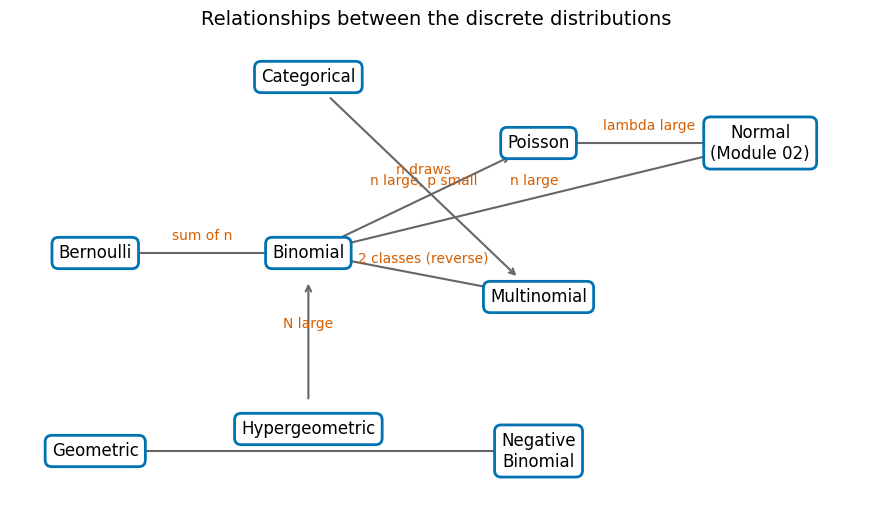

In [3]:
node_positions = {
    "Bernoulli": (0.1, 0.55), "Binomial": (0.35, 0.55), "Poisson": (0.62, 0.8), "Normal\n(Module 02)": (0.88, 0.8),
    "Hypergeometric": (0.35, 0.15), "Geometric": (0.1, 0.1), "Negative\nBinomial": (0.62, 0.1),
    "Categorical": (0.35, 0.95), "Multinomial": (0.62, 0.45),
}
edges = [
    ("Bernoulli", "Binomial", "sum of n"),
    ("Binomial", "Poisson", "n large, p small"),
    ("Poisson", "Normal\n(Module 02)", "lambda large"),
    ("Binomial", "Normal\n(Module 02)", "n large"),
    ("Hypergeometric", "Binomial", "N large"),
    ("Geometric", "Negative\nBinomial", "sum of r"),
    ("Categorical", "Multinomial", "n draws"),
    ("Binomial", "Multinomial", "2 classes (reverse)"),
]
fig, ax = plt.subplots(figsize=(11, 6))
for source, target, label in edges:
    (x1, y1), (x2, y2) = node_positions[source], node_positions[target]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=NEUTRAL, lw=1.5, shrinkA=22, shrinkB=22))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.03, label, ha="center", fontsize=10, color=HIGHLIGHT)
for name, (x, y) in node_positions.items():
    ax.text(x, y, name, ha="center", va="center", fontsize=12, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=MAIN, lw=2))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.axis("off")
ax.set_title("Relationships between the discrete distributions")
plt.show()

Quick numerical check of three of these links (maximum difference between PMFs):

In [4]:
k = np.arange(0, 15)
print("Binomial(1000, 0.003) vs Poisson(3):   ", np.max(np.abs(stats.binom(1000, 0.003).pmf(k) - stats.poisson(3).pmf(k))).round(6))
print("Hypergeom(10000, 3000, 10) vs Binom:   ", np.max(np.abs(stats.hypergeom(M=10000, n=3000, N=10).pmf(k[:11]) - stats.binom(10, 0.3).pmf(k[:11]))).round(6))
sum_of_geometrics = rng.geometric(0.3, size=(100_000, 3)).sum(axis=1)
nbinom_pmf = stats.nbinom(3, 0.3).pmf(np.arange(3, 25) - 3)
simulated_pmf = np.array([np.mean(sum_of_geometrics == t) for t in range(3, 25)])
print("sum of 3 Geometrics vs NegBin(3, 0.3): ", np.max(np.abs(simulated_pmf - nbinom_pmf)).round(4))

Binomial(1000, 0.003) vs Poisson(3):    0.000337
Hypergeom(10000, 3000, 10) vs Binom:    0.000134


sum of 3 Geometrics vs NegBin(3, 0.3):  0.0011


## 7. Decision flowchart: which discrete distribution?

Start at the top and answer each question about **how the data are generated**.

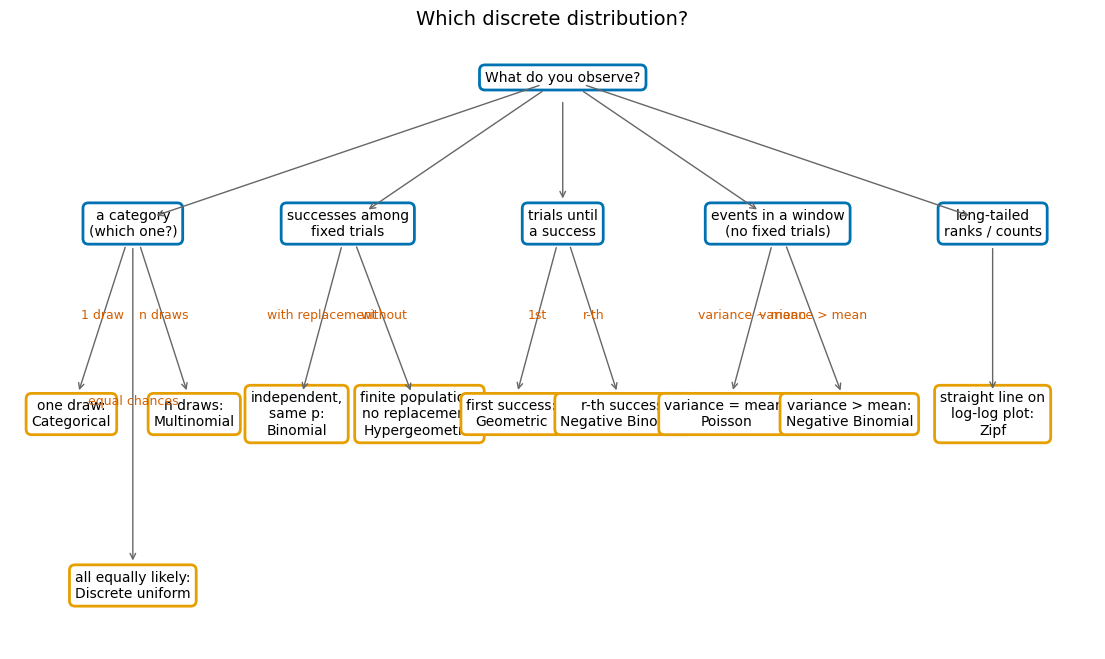

In [5]:
def draw_box(ax, x, y, text, kind="question"):
    """Draw one flowchart box: questions in blue, answers (distributions) in orange."""
    color = MAIN if kind == "question" else SIM
    ax.text(x, y, text, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=color, lw=2))

def draw_arrow(ax, x1, y1, x2, y2, label=""):
    """Draw an arrow between two boxes with a small label (Yes / No / choice)."""
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=NEUTRAL, shrinkA=18, shrinkB=18))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, label, fontsize=9, color=HIGHLIGHT, ha="center")

fig, ax = plt.subplots(figsize=(14, 8))
draw_box(ax, 0.5, 0.95, "What do you observe?")
branches = [(0.08, "a category\n(which one?)"), (0.29, "successes among\nfixed trials"), (0.5, "trials until\na success"),
            (0.71, "events in a window\n(no fixed trials)"), (0.92, "long-tailed\nranks / counts")]
for x, label in branches:
    draw_box(ax, x, 0.72, label)
    draw_arrow(ax, 0.5, 0.95, x, 0.72)

# Category branch
draw_box(ax, 0.02, 0.42, "one draw:\nCategorical", "answer"); draw_arrow(ax, 0.08, 0.72, 0.02, 0.42, "1 draw")
draw_box(ax, 0.14, 0.42, "n draws:\nMultinomial", "answer"); draw_arrow(ax, 0.08, 0.72, 0.14, 0.42, "n draws")
draw_box(ax, 0.08, 0.15, "all equally likely:\nDiscrete uniform", "answer"); draw_arrow(ax, 0.08, 0.72, 0.08, 0.15, "equal chances")
# Fixed trials branch
draw_box(ax, 0.24, 0.42, "independent,\nsame p:\nBinomial", "answer"); draw_arrow(ax, 0.29, 0.72, 0.24, 0.42, "with replacement")
draw_box(ax, 0.36, 0.42, "finite population,\nno replacement:\nHypergeometric", "answer"); draw_arrow(ax, 0.29, 0.72, 0.36, 0.42, "without")
# Waiting branch
draw_box(ax, 0.45, 0.42, "first success:\nGeometric", "answer"); draw_arrow(ax, 0.5, 0.72, 0.45, 0.42, "1st")
draw_box(ax, 0.56, 0.42, "r-th success:\nNegative Binomial", "answer"); draw_arrow(ax, 0.5, 0.72, 0.56, 0.42, "r-th")
# Window branch
draw_box(ax, 0.66, 0.42, "variance = mean:\nPoisson", "answer"); draw_arrow(ax, 0.71, 0.72, 0.66, 0.42, "variance ~ mean")
draw_box(ax, 0.78, 0.42, "variance > mean:\nNegative Binomial", "answer"); draw_arrow(ax, 0.71, 0.72, 0.78, 0.42, "variance > mean")
# Long tail
draw_box(ax, 0.92, 0.42, "straight line on\nlog-log plot:\nZipf", "answer"); draw_arrow(ax, 0.92, 0.72, 0.92, 0.42)
ax.set_xlim(-0.04, 1.02)
ax.set_ylim(0.05, 1.02)
ax.axis("off")
ax.set_title("Which discrete distribution?")
plt.show()

## 8. 2D visuals

Side by side, six PMFs with similar means (about 6) show how different the shapes are. Only the story changes.

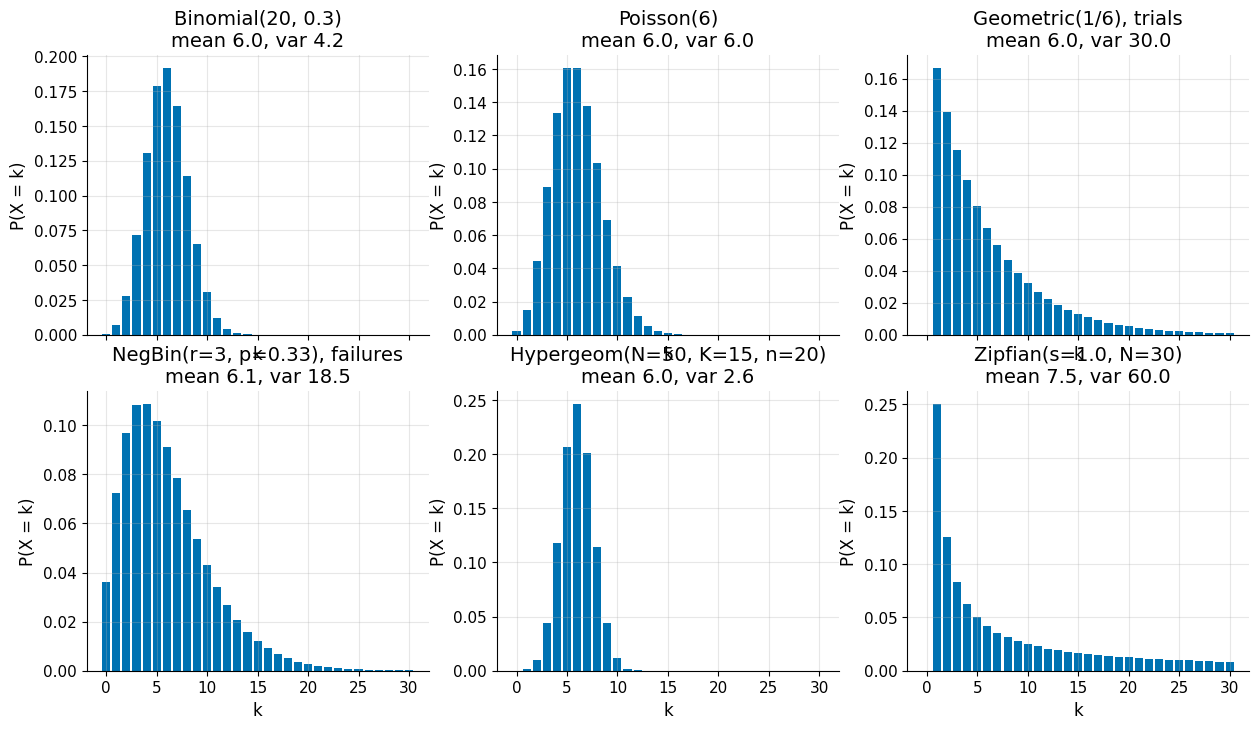

In [6]:
panel_dists = [
    ("Binomial(20, 0.3)", stats.binom(20, 0.3), 0),
    ("Poisson(6)", stats.poisson(6), 0),
    ("Geometric(1/6), trials", stats.geom(1 / 6), 1),
    ("NegBin(r=3, p=0.33), failures", stats.nbinom(3, 0.33), 0),
    ("Hypergeom(N=50, K=15, n=20)", stats.hypergeom(M=50, n=15, N=20), 0),
    ("Zipfian(s=1.0, N=30)", stats.zipfian(1.0, 30), 1),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, (name, dist, start) in zip(axes.ravel(), panel_dists):
    ks = np.arange(start, 31)
    ax.bar(ks, dist.pmf(ks), color=MAIN)
    ax.set_title(f"{name}\nmean {dist.mean():.1f}, var {dist.var():.1f}")
    ax.set_xlabel("k")
    ax.set_ylabel("P(X = k)")
plt.show()

## 9. 3D visuals (optional): side-by-side PMF surfaces

Binomial over (k, p), Poisson over (k, lambda) and Geometric over (k, p), the three one-parameter families on a common k axis.

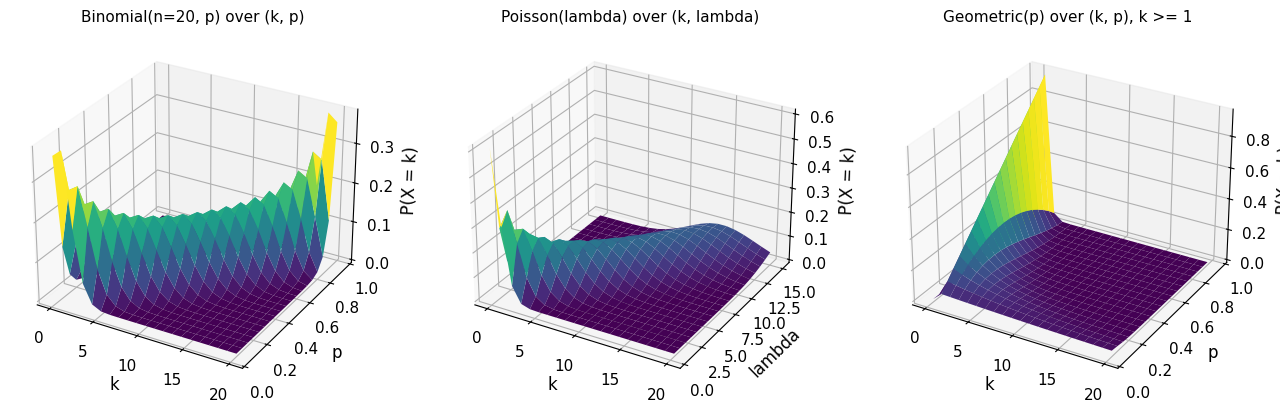

In [7]:
k_values = np.arange(0, 21)
grid_params = np.linspace(0.05, 0.95, 19)
K, P = np.meshgrid(k_values, grid_params)
poisson_lams = np.linspace(0.5, 15, 19)
K2, L = np.meshgrid(k_values, poisson_lams)

fig = plt.figure(figsize=(16, 5))
surfaces = [
    ("Binomial(n=20, p) over (k, p)", K, P, stats.binom.pmf(K, 20, P), "p"),
    ("Poisson(lambda) over (k, lambda)", K2, L, stats.poisson.pmf(K2, L), "lambda"),
    ("Geometric(p) over (k, p), k >= 1", K, P, np.where(K >= 1, stats.geom.pmf(np.maximum(K, 1), P), 0), "p"),
]
for position, (title, X, Y, Z, label) in enumerate(surfaces, start=1):
    ax = fig.add_subplot(1, 3, position, projection="3d")
    ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("k")
    ax.set_ylabel(label)
    ax.set_zlabel("P(X = k)")
    ax.view_init(elev=28, azim=-60)
plt.show()

Interactive version of the three surfaces in one Plotly figure: use the buttons to switch.

In [8]:
fig = go.Figure()
names = ["Binomial(n=20, p)", "Poisson(lambda)", "Geometric(p)"]
fig.add_trace(go.Surface(x=k_values, y=grid_params, z=stats.binom.pmf(K, 20, P), colorscale="Viridis", visible=True))
fig.add_trace(go.Surface(x=k_values, y=poisson_lams, z=stats.poisson.pmf(K2, L), colorscale="Plasma", visible=False))
fig.add_trace(go.Surface(x=k_values, y=grid_params, z=np.where(K >= 1, stats.geom.pmf(np.maximum(K, 1), P), 0), colorscale="Cividis", visible=False))
buttons = []
for index, name in enumerate(names):
    visible = [i == index for i in range(3)]
    buttons.append(dict(label=name, method="update", args=[{"visible": visible}, {"title": name + " PMF surface"}]))
fig.update_layout(title=names[0] + " PMF surface", width=800, height=560, updatemenus=[dict(buttons=buttons, direction="down", x=0.02, y=1.12)],
                  scene=dict(xaxis_title="k", yaxis_title="parameter", zaxis_title="P(X = k)"))
fig.show()

## 10. Simulation vs theory and the `scipy` cheat sheet

### 10.1 One simulation for every family
We draw 100,000 samples from each family with `numpy` and compare sample mean and variance with theory. They should agree to 2 or 3 digits.

In [9]:
simulations = {
    "Binomial(20, 0.3)": (rng.binomial(20, 0.3, size=100_000), stats.binom(20, 0.3)),
    "Geometric(0.3)": (rng.geometric(0.3, size=100_000), stats.geom(0.3)),
    "Poisson(6)": (rng.poisson(6, size=100_000), stats.poisson(6)),
    "Hypergeom(50, 15, 10)": (rng.hypergeometric(15, 35, 10, size=100_000), stats.hypergeom(M=50, n=15, N=10)),
    "NegBin(3, 0.3) failures": (rng.negative_binomial(3, 0.3, size=100_000), stats.nbinom(3, 0.3)),
}
for name, (samples, dist) in simulations.items():
    print(f"{name:26s} mean: sim {samples.mean():7.3f} theory {dist.mean():7.3f}   var: sim {samples.var():7.3f} theory {dist.var():7.3f}")

Binomial(20, 0.3)          mean: sim   5.993 theory   6.000   var: sim   4.200 theory   4.200
Geometric(0.3)             mean: sim   3.322 theory   3.333   var: sim   7.704 theory   7.778
Poisson(6)                 mean: sim   6.010 theory   6.000   var: sim   6.025 theory   6.000
Hypergeom(50, 15, 10)      mean: sim   3.002 theory   3.000   var: sim   1.719 theory   1.714
NegBin(3, 0.3) failures    mean: sim   6.999 theory   7.000   var: sim  23.327 theory  23.333


### 10.2 `scipy.stats` names at a glance

In [10]:
scipy_names = pd.DataFrame([
    ("Bernoulli", "stats.bernoulli(p)"), ("Binomial", "stats.binom(n, p)"), ("Geometric (trials)", "stats.geom(p)"),
    ("Negative Binomial (failures)", "stats.nbinom(n=r, p=p)"), ("Poisson", "stats.poisson(mu=lam)"),
    ("Hypergeometric", "stats.hypergeom(M=N, n=K, N=n)"), ("Discrete uniform", "stats.randint(low, high+1)"),
    ("Multinomial", "stats.multinomial(n, p)"), ("Zeta (infinite)", "stats.zipf(a=s)"), ("Zipfian (finite)", "stats.zipfian(a=s, n=N)"),
], columns=["distribution", "frozen scipy object"])
print(scipy_names.to_string(index=False))
print()
print("methods common to all frozen discrete distributions: pmf, logpmf, cdf, sf, ppf, rvs, mean, var, std, interval, stats, entropy")

                distribution            frozen scipy object
                   Bernoulli             stats.bernoulli(p)
                    Binomial              stats.binom(n, p)
          Geometric (trials)                  stats.geom(p)
Negative Binomial (failures)         stats.nbinom(n=r, p=p)
                     Poisson          stats.poisson(mu=lam)
              Hypergeometric stats.hypergeom(M=N, n=K, N=n)
            Discrete uniform     stats.randint(low, high+1)
                 Multinomial        stats.multinomial(n, p)
             Zeta (infinite)                stats.zipf(a=s)
            Zipfian (finite)        stats.zipfian(a=s, n=N)

methods common to all frozen discrete distributions: pmf, logpmf, cdf, sf, ppf, rvs, mean, var, std, interval, stats, entropy


## 11. Real-world worked example: 5 short scenarios

For each scenario: **identify** the distribution, **justify** the assumptions, **compute** one probability by formula, then check it against `scipy` with an `assert`. All numbers are illustrative.

| # | Scenario |
|---|---|
| 1 | An email filter flags 8 % of messages as spam. In a batch of 200, what is $P(\ge20\text{ spam})$? |
| 2 | A web server logs 3 errors per hour on average. What is $P(\ge6\text{ errors in an hour})$? |
| 3 | A sales rep closes 20 % of calls. What is the probability that the **3rd sale** happens within 12 calls? |
| 4 | A box of 40 circuit boards has 6 faulty ones. Testing 8 boards at random, what is $P(\ge2\text{ faulty})$? |
| 5 | A survey of 20 people with true opinion shares (Agree 0.5, Neutral 0.3, Disagree 0.2). What is $P(10\text{ agree},6\text{ neutral},4\text{ disagree})$? |

### 11.1 Identify and justify

| # | Distribution | Why |
|---|---|---|
| 1 | Binomial(200, 0.08) | fixed number of messages, each independently spam or not with the same $p$ |
| 2 | Poisson(3) | counts of independent events at a constant rate in a window, no fixed trial count |
| 3 | Negative Binomial($r=3$, $p=0.2$) (trials) | waiting for the 3rd success; the event "3rd sale within 12 calls" equals "at least 3 successes in 12 calls" |
| 4 | Hypergeometric($N=40$, $K=6$, $n=8$) | sampling without replacement from a finite lot, and the sample is 20 % of the lot |
| 5 | Multinomial(20; 0.5, 0.3, 0.2) | each respondent falls in exactly one of 3 categories, counts of all three are asked |

### 11.2 By hand (explicit formulas)
The formulas from each lesson, written as plain Python with `math`.

In [11]:
import math

# 1. Binomial: P(X >= 20) = 1 - sum_{k<20} C(200,k) 0.08^k 0.92^(200-k)
p1_hand = 1 - sum(math.comb(200, k) * 0.08**k * 0.92**(200 - k) for k in range(0, 20))

# 2. Poisson: P(X >= 6) = 1 - sum_{k<6} e^-3 3^k / k!
p2_hand = 1 - sum(math.exp(-3) * 3**k / math.factorial(k) for k in range(0, 6))

# 3. Negative Binomial in trials: P(T <= 12) = sum_{t=3}^{12} C(t-1, 2) 0.2^3 0.8^(t-3)
p3_hand = sum(math.comb(t - 1, 2) * 0.2**3 * 0.8**(t - 3) for t in range(3, 13))

# 4. Hypergeometric: P(X >= 2) = 1 - P(0) - P(1)
def hyper(k):
    return math.comb(6, k) * math.comb(34, 8 - k) / math.comb(40, 8)
p4_hand = 1 - hyper(0) - hyper(1)

# 5. Multinomial: 20! / (10! 6! 4!) * 0.5^10 * 0.3^6 * 0.2^4
p5_hand = math.factorial(20) / (math.factorial(10) * math.factorial(6) * math.factorial(4)) * 0.5**10 * 0.3**6 * 0.2**4
print([round(v, 5) for v in (p1_hand, p2_hand, p3_hand, p4_hand, p5_hand)])

[0.17887, 0.08392, 0.44165, 0.3442, 0.04419]


### 11.3 In code with `scipy`, and the asserts

In [12]:
p1_code = stats.binom(200, 0.08).sf(19)
p2_code = stats.poisson(3).sf(5)
p3_code = stats.nbinom(3, 0.2).cdf(12 - 3)            # failures convention: at most 9 failures before the 3rd success
p4_code = stats.hypergeom(M=40, n=6, N=8).sf(1)
p5_code = stats.multinomial(20, [0.5, 0.3, 0.2]).pmf([10, 6, 4])

for hand, code in [(p1_hand, p1_code), (p2_hand, p2_code), (p3_hand, p3_code), (p4_hand, p4_code), (p5_hand, p5_code)]:
    assert np.isclose(hand, code)
print("all five hand results match scipy")
print(pd.DataFrame({"scenario": [1, 2, 3, 4, 5], "probability": [p1_code, p2_code, p3_code, p4_code, p5_code]}).round(5).to_string(index=False))

all five hand results match scipy
 scenario  probability
        1      0.17887
        2      0.08392
        3      0.44165
        4      0.34420
        5      0.04419


Scenario 3 as a check of the Binomial link: P(3rd sale within 12 calls) equals P(at least 3 sales in 12 calls).

In [13]:
assert np.isclose(p3_code, stats.binom(12, 0.2).sf(2))
print("NegBin CDF at 12 trials equals Binomial(12, 0.2) P(X >= 3):", round(stats.binom(12, 0.2).sf(2), 5))

NegBin CDF at 12 trials equals Binomial(12, 0.2) P(X >= 3): 0.44165


### 11.4 Verify by simulation

In [14]:
trials = 200_000
sim1 = np.mean(rng.binomial(200, 0.08, size=trials) >= 20)
sim2 = np.mean(rng.poisson(3, size=trials) >= 6)
sim3 = np.mean(rng.negative_binomial(3, 0.2, size=trials) + 3 <= 12)
sim4 = np.mean(rng.hypergeometric(6, 34, 8, size=trials) >= 2)
sim5 = np.mean((lambda c: (c[:, 0] == 10) & (c[:, 1] == 6) & (c[:, 2] == 4))(rng.multinomial(20, [0.5, 0.3, 0.2], size=trials)))

for number, (exact, simulated) in enumerate([(p1_code, sim1), (p2_code, sim2), (p3_code, sim3), (p4_code, sim4), (p5_code, sim5)], start=1):
    print(f"scenario {number}: exact {exact:.5f}, simulated {simulated:.5f}")
    assert abs(exact - simulated) < 0.01

scenario 1: exact 0.17887, simulated 0.17960


scenario 2: exact 0.08392, simulated 0.08324
scenario 3: exact 0.44165, simulated 0.44028
scenario 4: exact 0.34420, simulated 0.34579
scenario 5: exact 0.04419, simulated 0.04406


### 11.5 Plots with the regions marked

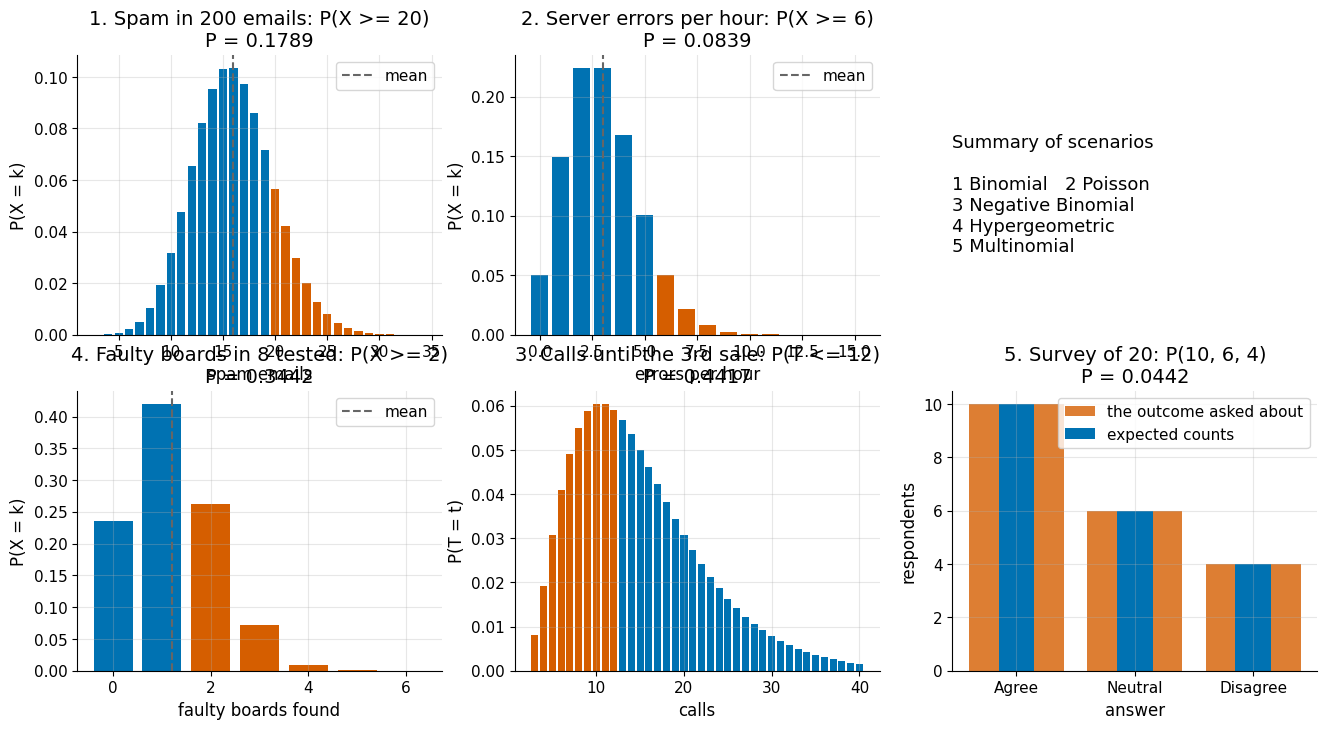

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

def shade_tail(ax, dist, ks, threshold, title, answer, xlabel):
    """Bar chart of a PMF with the tail k >= threshold in the highlight color."""
    ax.bar(ks, dist.pmf(ks), color=MAIN)
    tail = ks >= threshold
    ax.bar(ks[tail], dist.pmf(ks[tail]), color=HIGHLIGHT)
    ax.axvline(dist.mean(), color=NEUTRAL, linestyle="--", label="mean")
    ax.set_title(f"{title}\n{answer}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("P(X = k)")
    ax.legend()

shade_tail(axes[0, 0], stats.binom(200, 0.08), np.arange(3, 35), 20, "1. Spam in 200 emails: P(X >= 20)", f"P = {p1_code:.4f}", "spam emails")
shade_tail(axes[0, 1], stats.poisson(3), np.arange(0, 16), 6, "2. Server errors per hour: P(X >= 6)", f"P = {p2_code:.4f}", "errors per hour")
shade_tail(axes[1, 0], stats.hypergeom(M=40, n=6, N=8), np.arange(0, 7), 2, "4. Faulty boards in 8 tested: P(X >= 2)", f"P = {p4_code:.4f}", "faulty boards found")

trials_axis = np.arange(3, 41)
pmf_t = stats.nbinom(3, 0.2).pmf(trials_axis - 3)
axes[1, 1].bar(trials_axis, pmf_t, color=MAIN)
axes[1, 1].bar(trials_axis[trials_axis <= 12], pmf_t[trials_axis <= 12], color=HIGHLIGHT)
axes[1, 1].set_title(f"3. Calls until the 3rd sale: P(T <= 12)\nP = {p3_code:.4f}")
axes[1, 1].set_xlabel("calls")
axes[1, 1].set_ylabel("P(T = t)")

survey = stats.multinomial(20, [0.5, 0.3, 0.2])
axes[1, 2].bar(["Agree", "Neutral", "Disagree"], [10, 6, 4], color=HIGHLIGHT, alpha=0.8, label="the outcome asked about")
axes[1, 2].bar(["Agree", "Neutral", "Disagree"], survey.mean(), width=0.3, color=MAIN, label="expected counts")
axes[1, 2].set_title(f"5. Survey of 20: P(10, 6, 4)\nP = {p5_code:.4f}")
axes[1, 2].set_xlabel("answer")
axes[1, 2].set_ylabel("respondents")
axes[1, 2].legend()
axes[0, 2].axis("off")
axes[0, 2].text(0.0, 0.5, "Summary of scenarios\n\n1 Binomial   2 Poisson\n3 Negative Binomial\n4 Hypergeometric\n5 Multinomial", fontsize=13, va="center")
plt.show()

### 11.6 Interpretation and decision
1. **Spam:** 16 spam messages are expected in a batch of 200; seeing 20 or more happens in about **1 batch in 6** (P = 0.18), so that alone should not trigger a filter alarm.
2. **Server errors:** 6 or more errors in an hour has probability about **8 %**: an alert threshold of 6 would fire roughly once every 12 hours even when nothing is wrong. Raise it or alert on persistence.
3. **Sales:** the rep reaches the 3rd sale within 12 calls about **44 %** of the time; plan for about 15 calls on average (r/p = 15).
4. **Quality:** testing 8 of 40 boards finds 2 or more faulty ones with probability about **34 %** (the mean is 1.2 faulty), so a sample of 8 would miss a 15 % defect rate on many lots.
5. **Survey:** the exact split (10, 6, 4) matches the expected counts but has probability of only about **4 %**, since many nearby splits are almost as likely. The most likely single outcome is rarely very likely.

## 12. Where it is used

### Statistics
- Choosing the likelihood for count and categorical data is the first step in GLMs: Binomial or Bernoulli (logistic), Poisson, Negative Binomial, Multinomial (softmax regression).
- Goodness-of-fit and dispersion checks (variance / mean) guide the choice between Poisson and Negative Binomial.

### Data science
- Reporting: conversion counts (Binomial), event rates (Poisson), time to first purchase (Geometric), customer mix (Multinomial), long-tail popularity (Zipf).
- Sample-size and alert-threshold calculations use the tail probabilities of these families.

### ML and AI
- Likelihoods and losses: Bernoulli (binary cross-entropy), Categorical (softmax cross-entropy), Poisson (count loss), Multinomial (bag-of-words).
- Randomness inside models: dropout (Bernoulli), token sampling (Categorical), long-tailed vocabularies (Zipf).

## 13. Common pitfalls and misconceptions

- **Choosing by shape instead of story:** several families look alike (bell-shaped Binomial and Poisson). Decide from how the data are generated, then check with simulation.
- **Ignoring dependence:** the Binomial and Poisson assume independence; clustering breaks both.
- **Variance / mean is a diagnostic, not a proof:** it suggests overdispersion but also depends on sample size.
- **Convention traps:** trials vs failures (`geom`, `nbinom`), and `hypergeom` argument order.
- **A 'rare event' is not automatically Poisson:** it also needs a constant rate.

## 14. Exercises (mixed practice)

For each, name the distribution, then compute the answer.

1. A fair coin is flipped 15 times. What is the probability of at least 10 heads?
2. A helpdesk gets 4 tickets per hour on average. What is the probability of no tickets in a 30-minute window?
3. A basketball player makes 65 % of free throws. What is the probability that the first miss happens after the 5th shot?
4. A drawer holds 10 black and 6 white socks. You grab 4 in the dark. What is the probability of exactly 2 black?
5. A die is rolled 12 times. What is the probability each face appears exactly twice?
6. Daily counts of customer complaints have mean 3 and variance 9. Which distribution would you try, and what are plausible parameters?
7. (Harder) A call center gets 20 calls per hour (Poisson). Each caller is a repeat caller with probability 0.25. What is the distribution of repeat callers per hour? Find the probability of more than 8.
8. (Harder) A recruiter interviews candidates until 2 are hired; each candidate is hired with probability 0.15. What is the distribution of the number of interviews? What is the probability it takes more than 20 interviews?

Solutions are at the end.

## 15. Summary table

| Distribution | Use when | Mean | Variance | `scipy` |
|---|---|---|---|---|
| Bernoulli | one yes/no trial | p | p(1-p) | `bernoulli(p)` |
| Binomial | successes in n independent trials | np | np(1-p) | `binom(n, p)` |
| Geometric | trials until the first success | 1/p | (1-p)/p^2 | `geom(p)` |
| Negative Binomial | trials until the r-th success; overdispersed counts | r/p | r(1-p)/p^2 | `nbinom(r, p)` |
| Poisson | events in a window, constant rate | lambda | lambda | `poisson(lam)` |
| Hypergeometric | successes, sampling without replacement | nK/N | n(K/N)(1-K/N)(N-n)/(N-1) | `hypergeom(M, n, N)` |
| Discrete uniform | equally likely outcomes | (a+b)/2 | ((b-a+1)^2-1)/12 | `randint(a, b+1)` |
| Categorical / Multinomial | one draw / counts over k classes | n p_j | n p_j (1-p_j) | `multinomial(n, p)` |
| Zipf | heavy-tailed ranks | zeta(s-1)/zeta(s) (s>2) | needs s>3 | `zipf(a)`, `zipfian(a, n)` |

## Solutions

In [16]:
print("1 Binomial(15, 0.5):", stats.binom(15, 0.5).sf(9))
print("2 Poisson(2):       ", stats.poisson(2).pmf(0), " = exp(-2) =", np.exp(-2))
print("3 Geometric(0.35) for the first miss: P(first miss after shot 5) =", 0.65**5, stats.geom(0.35).sf(5))
print("4 Hypergeom:        ", stats.hypergeom(M=16, n=10, N=4).pmf(2))
print("5 Multinomial:      ", stats.multinomial(12, [1 / 6] * 6).pmf([2] * 6))
r6 = 3**2 / (9 - 3)
p6 = 3 / 9
print(f"6 NegBin moments: r = {r6:.2f}, p = {p6:.3f}; P(0) = {stats.nbinom(r6, p6).pmf(0):.4f} vs Poisson(3) {stats.poisson(3).pmf(0):.4f}")
print("7 Poisson(5):       ", stats.poisson(20 * 0.25).sf(8))
print("8 NegBin(2, 0.15) trials > 20:", 1 - stats.nbinom(2, 0.15).cdf(20 - 2))

1 Binomial(15, 0.5): 0.15087890624999997
2 Poisson(2):        0.1353352832366127  = exp(-2) = 0.1353352832366127
3 Geometric(0.35) for the first miss: P(first miss after shot 5) = 0.11602906250000002 0.11602906250000003
4 Hypergeom:         0.3708791208791209
5 Multinomial:       0.003438285893918611
6 NegBin moments: r = 1.50, p = 0.333; P(0) = 0.1925 vs Poisson(3) 0.0498
7 Poisson(5):        0.0680936347218484
8 NegBin(2, 0.15) trials > 20: 0.17555787608868256


**1.** Binomial($15,0.5$), $P(X\ge10)\approx0.1509$.

**2.** Poisson($\lambda=2$ per half hour): $P(0)=e^{-2}\approx0.1353$.

**3.** Geometric: the first miss (probability 0.35 per shot) occurs after shot 5 if the first 5 shots are makes: $0.65^5\approx0.1160$.

**4.** Hypergeometric($N=16,K=10,n=4$): $\binom{10}2\binom62/\binom{16}4\approx0.3709$.

**5.** Multinomial($12$; $1/6$ each): $\frac{12!}{(2!)^6}6^{-12}\approx0.0034$.

**6.** Variance (9) is three times the mean (3), so Poisson is unsuitable. Negative Binomial by moments: $r=\mu^2/(v-\mu)=1.5$, $p=\mu/v=1/3$; it puts far more mass on 0 than Poisson does.

**7.** Thinning gives Poisson($20\times0.25=5$); $P(X>8)\approx0.0681$.

**8.** Negative Binomial($r=2$, $p=0.15$) in trials; $P(T>20)\approx0.1756$.